# Notebook 08: Extended Model Comparison — Random Forest and LightGBM
**Project F1: Electricity Consumption Analysis and Forecasting in Morocco**

## Purpose and evaluation contract
Add two model families, each with and without historical weather: four configurations and twelve estimators across three zones. All 144 next-day forecasts are issued together at **23:50 the previous day**, immediately after that reading. History updates daily; models are fitted through August and remain frozen during validation and testing. This convention assumes negligible reporting and computation delay. Future observed weather is unavailable.

**This is an exploratory extension.** November–December outcomes and earlier forecast errors were already examined in Notebook 07 before these families were chosen. Locking settings and selecting using validation prevents further test-driven adjustments within this experiment; it does not restore an untouched test set. New data would be needed for independent confirmation.

Random Forest was motivated by the Tetouan paper, but our features and forecast issue rules differ. The paper's stated 75%/25% split alone does not establish whether dates were randomly mixed.

## 1. Setup
Use the project `.venv` and complete Notebooks 04–07 first. LightGBM 4.7.0 is included in `requirements.txt`. Other environments need the requirements installed and the corresponding interpreter selected in VS Code.

Random Forest averages separately trained trees. LightGBM builds successive trees to correct errors. See the [Random Forest documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html) and [LightGBM documentation](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMRegressor.html).

In [1]:
import sys, json, hashlib, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, lightgbm, joblib
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display
p = Path.cwd().resolve()
ROOT = next(x for x in [p, *p.parents] if (x/'src/config.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.config import PROCESSED_DIR, FIGURES_DIR, TABLES_DIR, MODELS_DIR, ZONES
SERIES = [*ZONES, 'total']
SLUG = '08_extended_model_comparison'
FIG, TAB, MOD = FIGURES_DIR/SLUG, TABLES_DIR/SLUG, MODELS_DIR/'08_daily_batch'
for folder in [FIG, TAB, MOD]: folder.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'svg.fonttype': 'none'})
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def table(frame, name): frame.to_csv(TAB/f'{name}.csv', index=False, encoding='utf-8')
def figure(fig, name):
    fig.tight_layout()
    for ext in ['png', 'svg']: fig.savefig(FIG/f'{name}.{ext}', dpi=180, bbox_inches='tight')
    plt.show(); plt.close(fig)
def freeze(path, payload):
    if path.exists():
        assert json.loads(path.read_text(encoding='utf-8')) == payload, f'Frozen experiment differs: {path}'
    else: path.write_text(json.dumps(payload, indent=2, allow_nan=False), encoding='utf-8')
versions = dict(python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__,
                sklearn=sklearn.__version__, lightgbm=lightgbm.__version__)
print('Python:', sys.executable)
print('Versions:', versions)

Python: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\.venv\Scripts\python.exe
Versions: {'python': '3.13.15', 'numpy': '2.5.4', 'pandas': '3.1.0', 'sklearn': '1.9.1', 'lightgbm': '4.7.0'}


## 2. Verify inputs and forecast timing
There are 33,840 training targets, 8,784 validation targets and 8,640 test targets. Each day has 144 readings and one issue time. Predictor lists and availability checks come from Notebook 04.

The selected Notebook 05 baseline uses the previous day for Zones 1–2 and the previous seven days' same-clock mean for Zone 3. It is not a pure previous-day model in every zone.

In [2]:
mp = PROCESSED_DIR/'tetuan_features_daily_batch_manifest.json'
manifest = json.loads(mp.read_text(encoding='utf-8'))
feature_path, source_path = PROCESSED_DIR/manifest['feature_file'], PROCESSED_DIR/manifest['source_file']
assert manifest['design_id'] == 'daily_batch_2350'
assert sha(feature_path) == manifest['feature_sha256'] and sha(source_path) == manifest['source_sha256']
old_selection_path = MODELS_DIR/'06_daily_batch/model_selection_daily_batch.json'
old_selection = json.loads(old_selection_path.read_text(encoding='utf-8'))
bp = MODELS_DIR/'05_baselines_daily_batch/baseline_selection_daily_batch.json'
baseline_contract = json.loads(bp.read_text(encoding='utf-8'))
pp = MODELS_DIR/'07_frozen_evaluation/frozen_plan_daily_batch.json'
peak_plan = json.loads(pp.read_text(encoding='utf-8'))
assert old_selection['feature_manifest_sha256'] == baseline_contract['feature_manifest_sha256'] == sha(mp)
assert sha(old_selection_path) == peak_plan['model_selection_sha256']
assert sha(bp) == peak_plan['baseline_selection_sha256']
for spec in peak_plan['model_artifacts'].values(): assert sha(ROOT/spec['relative_path']) == spec['sha256']
panel = pd.read_parquet(feature_path)
frames = {s: panel.loc[panel.split.eq(s)].copy().reset_index(drop=True) for s in ['train', 'validation', 'test']}
train, val = frames['train'], frames['validation']
assert [len(d) for d in frames.values()] == [33840, 8784, 8640]
assert train.target_time.max() <= val.origin_time.min()
assert val.target_time.max() <= frames['test'].origin_time.min()
for d in frames.values():
    assert d.target_time.is_unique and d.target_time.is_monotonic_increasing
    daily = d.groupby(d.target_time.dt.normalize())
    assert daily.size().eq(144).all() and daily.origin_time.nunique().eq(1).all()
    assert d.origin_time.eq(d.target_time.dt.normalize()-pd.Timedelta(minutes=10)).all()
    assert ((d.target_time-d.origin_time)/pd.Timedelta(minutes=10)).eq(d.lead_steps).all()
groups = manifest['feature_groups']
base_features = groups['calendar']+groups['load_history']
all_features = base_features+groups['weather_history']
assert len(base_features) == 57 and len(all_features) == 72
assert not set(all_features).intersection(manifest['target_columns'])
assert np.isfinite(panel[all_features].to_numpy()).all()
old_val_path = PROCESSED_DIR/'model_validation_daily_batch.parquet'
old_test_path = PROCESSED_DIR/'peak_warning_backtest_daily_batch.parquet'
old_val = pd.read_parquet(old_val_path)
protected_paths = [mp, feature_path, source_path, old_selection_path, bp, pp, old_val_path, old_test_path]
protected_paths += sorted((MODELS_DIR/'06_daily_batch').glob('*.joblib'))
protected_hashes = {str(x.relative_to(ROOT)): sha(x) for x in protected_paths}
splits = pd.DataFrame([dict(split=s, rows=len(d), days=len(d)//144,
                          first_target=str(d.target_time.min()), last_target=str(d.target_time.max())) for s,d in frames.items()])
table(splits, '01_split_summary'); display(splits)

,split,rows,days,first_target,last_target
0,train,33840,235,2017-01-09 00:00:00,2017-08-31 23:50:00
1,validation,8784,61,2017-09-01 00:00:00,2017-10-31 23:50:00
2,test,8640,60,2017-11-01 00:00:00,2017-12-30 23:50:00


## 3. Lock settings before fitting
Both families predict **actual minus yesterday's same-slot demand**. Add the available anchor back and clip negative final forecasts at zero. This holds target construction constant with Notebook 06.

Random Forest: 200 trees, maximum depth 12, minimum 20 rows per leaf, 80% of features considered per split. Bootstrap sampling uses training rows only; out-of-bag scores are not used for temporal evaluation.

LightGBM: 150 trees, learning rate 0.05, 15 leaves, minimum 50 rows per leaf, L2 regularisation 1, no early stopping. These are modest declared settings, not optimised winners. Both train with squared-error objectives; selection uses validation MAE.

Save settings, feature lists, versions and input hashes before fitting. Reruns must match this plan and reuse saved models; a genuinely different experiment needs its own documented plan and directory.

In [3]:
rf_params = dict(n_estimators=200, max_depth=12, min_samples_leaf=20, max_features=.8,
                 bootstrap=True, criterion='squared_error', oob_score=False, random_state=42, n_jobs=2)
lgb_params = dict(n_estimators=150, learning_rate=.05, num_leaves=15, min_child_samples=50,
                  reg_lambda=1., objective='regression', random_state=42, n_jobs=2,
                  deterministic=True, force_col_wise=True, verbosity=-1)
candidates = {'rf_no_weather': ('rf', base_features), 'rf_with_weather': ('rf', all_features),
              'lgbm_no_weather': ('lgbm', base_features), 'lgbm_with_weather': ('lgbm', all_features)}
plan = dict(design_id=manifest['design_id'], issue_clock=manifest['issue_clock'],
            exploratory_after_prior_test_inspection=True, prior_test_forecast_errors_seen=True,
            fit_latest_label=str(train.target_time.max()), rf_params=rf_params, lgbm_params=lgb_params,
            candidates={k: dict(family=v[0], features=v[1]) for k,v in candidates.items()},
            training_target='actual minus previous-day anchor; final forecast clipped at zero',
            selection='validation MAE per zone; exact ties prefer baseline then original then new candidates',
            refit_after_validation=False, early_stopping=False, versions=versions,
            protected_inputs=protected_hashes, splits=splits.to_dict(orient='records'))
plan_path = MOD/'experiment_plan.json'
freeze(plan_path, plan)
plan_hash = sha(plan_path)
print('Plan locked:', plan_path)

Plan locked: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\models\08_daily_batch\experiment_plan.json


## 4. Fit or reload twelve training-only models
Only training rows enter `.fit()`. The weather variants otherwise share the same settings. Reload each saved model and verify its validation predictions. Models stay frozen during both evaluation periods.

In [4]:
def actual_frame(d):
    a = d.set_index('target_time')[[f'y_{z}' for z in ZONES]].rename(columns={f'y_{z}':z for z in ZONES})
    a['total'] = a[ZONES].sum(axis=1)
    return a[SERIES]
def predict_bundle(b, d):
    assert b['design_id'] == manifest['design_id'] and b['fit_latest_label'] == str(train.target_time.max())
    with threadpool_limits(limits=2): correction = b['model'].predict(d[b['feature_columns']])
    return np.maximum(0, d[b['anchor_column']].to_numpy()+correction)
actual_val = actual_frame(val)
val_predictions = {}
for name in ['baseline', 'ridge_no_weather', 'ridge_with_weather', 'boost_no_weather', 'boost_with_weather']:
    sub = old_val.loc[old_val.candidate.eq(name)]
    forecast = sub.pivot(index='target_time', columns='series', values='prediction').reindex(index=actual_val.index, columns=SERIES)
    observed = sub.pivot(index='target_time', columns='series', values='actual').reindex_like(actual_val)
    np.testing.assert_allclose(observed, actual_val)
    assert forecast.notna().all().all()
    val_predictions[name] = forecast
bundles, fit_rows = {}, []
for name,(family,columns) in candidates.items():
    forecast = pd.DataFrame(index=actual_val.index)
    for zone in ZONES:
        path = MOD/f'{name}_{zone}.joblib'
        if path.exists():
            b = joblib.load(path)
            assert b['plan_sha256'] == plan_hash
        else:
            model = RandomForestRegressor(**rf_params) if family == 'rf' else LGBMRegressor(**lgb_params)
            started = time.perf_counter()
            residual = train[f'y_{zone}'].to_numpy()-train[f'{zone}_target_lag_1d'].to_numpy()
            with threadpool_limits(limits=2): model.fit(train[columns], residual)
            b = dict(model=model, feature_columns=columns, anchor_column=f'{zone}_target_lag_1d',
                     fit_latest_label=str(train.target_time.max()), design_id=manifest['design_id'],
                     plan_sha256=plan_hash, fit_seconds=time.perf_counter()-started)
            joblib.dump(b, path, compress=3)
        assert b['feature_columns'] == columns and b['anchor_column'] == f'{zone}_target_lag_1d'
        forecast[zone] = predict_bundle(b, val)
        np.testing.assert_allclose(predict_bundle(joblib.load(path), val), forecast[zone], rtol=1e-10, atol=1e-8)
        bundles[(name,zone)] = b
        fit_rows.append(dict(candidate=name, zone=zone, features=len(columns), training_rows=len(train), fit_seconds=b['fit_seconds']))
        print('Ready:', name, zone, flush=True)
    forecast['total'] = forecast[ZONES].sum(axis=1)
    val_predictions[name] = forecast
fit_report = pd.DataFrame(fit_rows)
table(fit_report, '02_fit_report'); display(fit_report.round(2))

Ready: rf_no_weather zone1
Ready: rf_no_weather zone2
Ready: rf_no_weather zone3
Ready: rf_with_weather zone1
Ready: rf_with_weather zone2
Ready: rf_with_weather zone3
Ready: lgbm_no_weather zone1
Ready: lgbm_no_weather zone2
Ready: lgbm_no_weather zone3
Ready: lgbm_with_weather zone1
Ready: lgbm_with_weather zone2
Ready: lgbm_with_weather zone3


,candidate,zone,features,training_rows,fit_seconds
0,rf_no_weather,zone1,57,33840,96.72
1,rf_no_weather,zone2,57,33840,95.57
2,rf_no_weather,zone3,57,33840,111.72
3,rf_with_weather,zone1,72,33840,122.18
4,rf_with_weather,zone2,72,33840,127.86
5,rf_with_weather,zone3,72,33840,133.98
6,lgbm_no_weather,zone1,57,33840,2.97
7,lgbm_no_weather,zone2,57,33840,2.91
8,lgbm_no_weather,zone3,57,33840,2.71
9,lgbm_with_weather,zone1,72,33840,3.79


## 5. Score all candidates on identical validation targets
MAE is primary. MSE penalises large errors; RMSE is its square root in demand units, with identical rankings. MAPE averages percentage errors per reading; WAPE divides summed absolute errors by summed actual demand. Positive bias means overprediction. All actual values here are positive.

Combined demand is the sum of the zone forecasts. Opposing errors can cancel, so inspect zones too. Units are reported as source units because they have not been independently confirmed.

,period,candidate,series,MAE,MSE,RMSE,MAPE_pct,WAPE_pct,bias,MAE_improvement_vs_baseline_pct
0,validation,baseline,zone1,1304.418,3.345601e+06,1829.098,4.083,3.940,41.941,0.000
1,validation,baseline,zone2,1371.172,3.817198e+06,1953.765,6.890,6.581,-84.848,0.000
2,validation,baseline,zone3,711.299,1.226327e+06,1107.397,5.270,5.052,409.291,0.000
3,validation,baseline,total,2333.079,1.217889e+07,3489.827,3.612,3.430,366.383,0.000
4,validation,ridge_no_weather,zone1,1519.065,3.402227e+06,1844.513,4.678,4.588,-645.345,-16.455
5,validation,ridge_no_weather,zone2,2776.221,9.406493e+06,3067.001,13.304,13.325,-2612.509,-102.471
6,validation,ridge_no_weather,zone3,940.185,1.318772e+06,1148.378,6.904,6.678,-742.867,-32.179
7,validation,ridge_no_weather,total,4318.386,2.317413e+07,4813.951,6.479,6.348,-4000.721,-85.094
8,validation,ridge_with_weather,zone1,1436.897,3.179962e+06,1783.245,4.418,4.340,-592.030,-10.156
9,validation,ridge_with_weather,zone2,2796.698,9.555852e+06,3091.254,13.409,13.423,-2631.625,-103.964


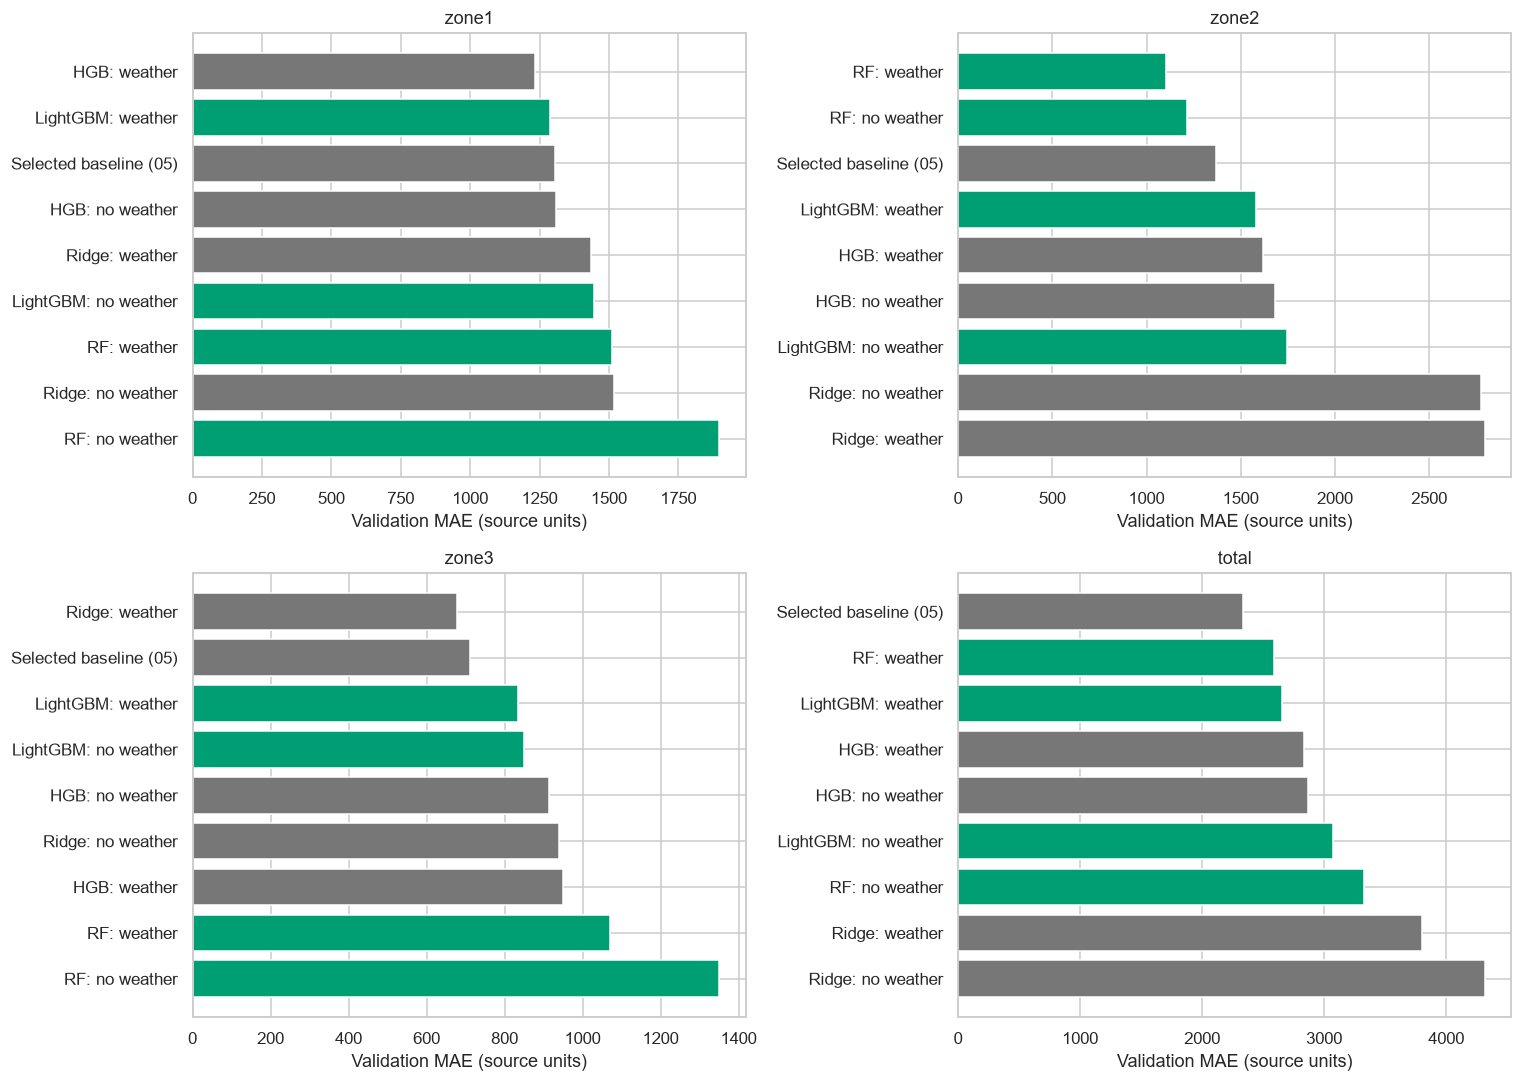

In [5]:
def metrics(y,p):
    y,p = np.asarray(y,dtype=float), np.asarray(p,dtype=float)
    assert y.ndim == p.ndim == 1 and y.shape == p.shape
    assert np.isfinite(y).all() and np.isfinite(p).all() and (y>0).all()
    e = p-y; mse = np.mean(e**2)
    return dict(MAE=np.abs(e).mean(), MSE=mse, RMSE=np.sqrt(mse), MAPE_pct=100*np.mean(np.abs(e)/y),
                WAPE_pct=100*np.abs(e).sum()/y.sum(), bias=e.mean())
assert metrics([100,200],[110,180])['MSE'] == 250
def score(predictions, actual, period):
    rows = []
    for name,f in predictions.items():
        pd.testing.assert_index_equal(f.index, actual.index)
        np.testing.assert_allclose(f[ZONES].sum(axis=1), f.total)
        for z in SERIES: rows.append(dict(period=period, candidate=name, series=z, **metrics(actual[z],f[z])))
    result = pd.DataFrame(rows)
    ref = result.loc[result.candidate.eq('baseline')].set_index('series').MAE
    result['MAE_improvement_vs_baseline_pct'] = [100*(1-r.MAE/ref[r.series]) for r in result.itertuples()]
    return result
val_scores = score(val_predictions, actual_val, 'validation')
table(val_scores,'03_validation_all_candidates'); display(val_scores.round(3))
labels = {'baseline':'Selected baseline (05)', 'ridge_no_weather':'Ridge: no weather', 'ridge_with_weather':'Ridge: weather',
          'boost_no_weather':'HGB: no weather', 'boost_with_weather':'HGB: weather',
          'rf_no_weather':'RF: no weather', 'rf_with_weather':'RF: weather',
          'lgbm_no_weather':'LightGBM: no weather', 'lgbm_with_weather':'LightGBM: weather',
          'original_selected':'Original selection (06)', 'rf_selected':'RF: validation choice',
          'lgbm_selected':'LightGBM: validation choice', 'extended_selected':'Extended selection (08)'}
fig,axes = plt.subplots(2,2,figsize=(14,10))
for ax,z in zip(axes.flat,SERIES):
    d = val_scores.loc[val_scores.series.eq(z)].sort_values('MAE',ascending=False)
    ax.barh(d.candidate.map(labels),d.MAE,color=['#009E73' if n in candidates else '#777777' for n in d.candidate])
    ax.set(title=z,xlabel='Validation MAE (source units)')
figure(fig,'01_validation_mae_all_candidates')

## 6. Weather ablation and validation selection
Positive weather improvement means adding historical weather lowered MAE with settings held fixed. This is predictive evidence for one period, not a causal claim.

Choose the weather option per zone within each new family. Also choose an extended strategy from all nine candidates, retaining the baseline as eligible. Exact ties follow the displayed candidate order. Per-zone choices need not minimise combined MAE. Scores on the validation data used for selection are optimistic.

,family,zone,weather_MAE_improvement_pct,weather_RMSE_improvement_pct
0,rf,zone1,20.327,17.426
1,rf,zone2,9.218,8.417
2,rf,zone3,20.786,16.923
3,lgbm,zone1,10.916,6.756
4,lgbm,zone2,9.462,7.742
5,lgbm,zone3,1.714,0.329


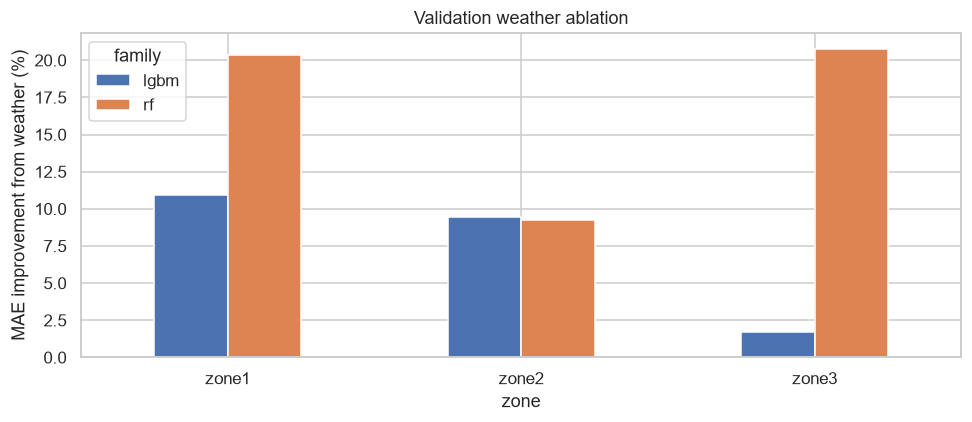

,strategy,zone,candidate
0,original_selected,zone1,boost_with_weather
1,original_selected,zone2,baseline
2,original_selected,zone3,ridge_with_weather
3,rf_selected,zone1,rf_with_weather
4,rf_selected,zone2,rf_with_weather
5,rf_selected,zone3,rf_with_weather
6,lgbm_selected,zone1,lgbm_with_weather
7,lgbm_selected,zone2,lgbm_with_weather
8,lgbm_selected,zone3,lgbm_with_weather
9,extended_selected,zone1,boost_with_weather


In [6]:
rows = []
for family in ['rf','lgbm']:
    for z in ZONES:
        s = val_scores.loc[val_scores.series.eq(z)].set_index('candidate')
        a,b = s.loc[f'{family}_no_weather'], s.loc[f'{family}_with_weather']
        rows.append(dict(family=family,zone=z,weather_MAE_improvement_pct=100*(1-b.MAE/a.MAE),
                         weather_RMSE_improvement_pct=100*(1-b.RMSE/a.RMSE)))
ablation = pd.DataFrame(rows)
table(ablation,'04_weather_ablation'); display(ablation.round(3))
fig,ax = plt.subplots(figsize=(9,4))
ablation.pivot(index='zone',columns='family',values='weather_MAE_improvement_pct').plot.bar(ax=ax,rot=0)
ax.axhline(0,color='black',linewidth=.8)
ax.set(title='Validation weather ablation',ylabel='MAE improvement from weather (%)')
figure(fig,'02_weather_ablation')
def choose(names):
    return {z:val_scores.loc[val_scores.series.eq(z)].set_index('candidate').loc[names,'MAE'].idxmin() for z in ZONES}
choices = {'original_selected':old_selection['selected_by_zone'],
           'rf_selected':choose(['rf_no_weather','rf_with_weather']),
           'lgbm_selected':choose(['lgbm_no_weather','lgbm_with_weather']),
           'extended_selected':choose(list(val_predictions))}
for name,selection in choices.items():
    f = pd.DataFrame({z:val_predictions[selection[z]][z] for z in ZONES},index=actual_val.index)
    f['total'] = f[ZONES].sum(axis=1)
    val_predictions[name] = f
selection_table = pd.DataFrame([dict(strategy=n,zone=z,candidate=c) for n,s in choices.items() for z,c in s.items()])
table(selection_table,'05_validation_choices'); display(selection_table)
val_scores = score(val_predictions,actual_val,'validation')
table(val_scores,'06_validation_including_strategies')

### Measured validation findings

The weather options selected using validation MAE were:

- **Random Forest:** zone1: `rf_with_weather`; zone2: `rf_with_weather`; zone3: `rf_with_weather`.
- **LightGBM:** zone1: `lgbm_with_weather`; zone2: `lgbm_with_weather`; zone3: `lgbm_with_weather`.
- **Extended selection (08):** zone1: `boost_with_weather`; zone2: `rf_with_weather`; zone3: `ridge_with_weather`.

| Strategy | Combined validation MAE | Change relative to baseline |
|---|---:|---|
| Selected baseline (05) | 2,333.08 | Reference |
| Original selection (06) | 2,177.87 | 6.65% lower than the baseline |
| Random Forest | 2,591.65 | 11.08% higher than the baseline |
| LightGBM | 2,653.27 | 13.72% higher than the baseline |
| Extended selection (08) | 1,914.01 | 17.96% lower than the baseline |

Weather effects differ by family and zone. The ablation table reports the direction and size of each comparison. These choices use validation outcomes; the later-period table is the next check, not another selection step.

## 7. Freeze selections before extension test predictions
The first lock records settings before fitting. This second lock records validation choices and fitted-model hashes before calculating extension test errors. Earlier test exposure remains disclosed; these files are procedural records, not a claim of independent confirmation.

In [7]:
new_model_hashes = {str(p.relative_to(ROOT)):sha(p) for p in sorted(MOD.glob('*.joblib'))}
assert len(new_model_hashes) == 12
selection_lock = dict(experiment_plan_sha256=plan_hash, choices=choices, model_hashes=new_model_hashes,
                      test_already_inspected_before_extension=True, selection_metric='validation MAE per zone',
                      test_use='exploratory fixed comparison; no reselection from test metrics',
                      fit_latest_label=str(train.target_time.max()))
selection_path = MOD/'validation_selection.json'
freeze(selection_path,selection_lock)
print('Selections locked:',choices)

Selections locked: {'original_selected': {'zone1': 'boost_with_weather', 'zone2': 'baseline', 'zone3': 'ridge_with_weather'}, 'rf_selected': {'zone1': 'rf_with_weather', 'zone2': 'rf_with_weather', 'zone3': 'rf_with_weather'}, 'lgbm_selected': {'zone1': 'lgbm_with_weather', 'zone2': 'lgbm_with_weather', 'zone3': 'lgbm_with_weather'}, 'extended_selected': {'zone1': 'boost_with_weather', 'zone2': 'rf_with_weather', 'zone3': 'ridge_with_weather'}}


## 8. Exploratory November–December evaluation
Score all four new configurations and the previously selected strategies on the same 8,640 targets. Keep the August-fitted parameters and validation choices fixed. A rerun reproduces this experiment; it does not perform another model search. Report every configuration, including any worse than the baseline.

,period,candidate,series,MAE,MSE,RMSE,MAPE_pct,WAPE_pct,bias,MAE_improvement_vs_baseline_pct
0,test_exploratory,baseline,zone1,977.309,2.155560e+06,1468.182,3.418,3.369,39.305,0.000
1,test_exploratory,baseline,zone2,1132.873,2.935196e+06,1713.241,5.105,4.829,5.245,0.000
2,test_exploratory,baseline,zone3,854.125,1.928279e+06,1388.625,7.100,7.145,64.543,0.000
3,test_exploratory,baseline,total,2159.186,1.046471e+07,3234.920,3.456,3.351,109.093,0.000
4,test_exploratory,original_selected,zone1,2444.484,9.651590e+06,3106.701,8.278,8.425,2310.875,-150.124
5,test_exploratory,original_selected,zone2,1132.873,2.935196e+06,1713.241,5.105,4.829,5.245,0.000
6,test_exploratory,original_selected,zone3,1694.588,3.935227e+06,1983.741,14.521,14.176,-1611.846,-98.400
7,test_exploratory,original_selected,total,2512.191,1.144465e+07,3382.994,3.938,3.899,704.275,-16.349
8,test_exploratory,rf_no_weather,zone1,2140.503,9.200030e+06,3033.155,7.471,7.378,1791.244,-119.020
9,test_exploratory,rf_no_weather,zone2,1118.309,2.296446e+06,1515.403,5.065,4.767,224.135,1.286


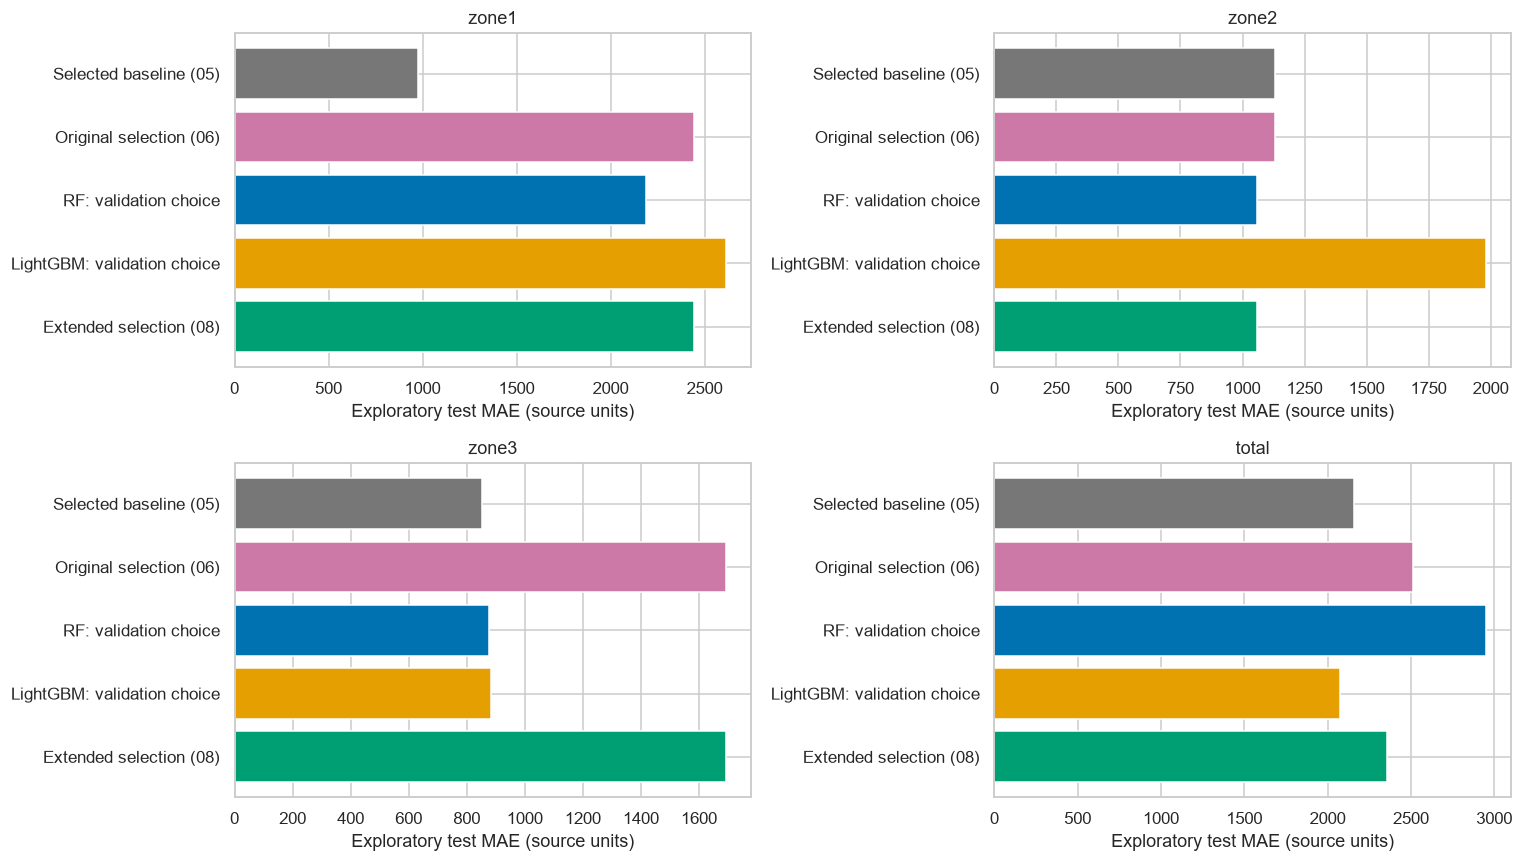

In [8]:
test = frames['test']
actual_test = actual_frame(test)
old_test = pd.read_parquet(old_test_path)
test_predictions = {}
for old_name,name in [('baseline','baseline'),('selected','original_selected')]:
    sub = old_test.loc[old_test.period.eq('test') & old_test.method.eq(old_name)]
    f = sub.pivot(index='target_time',columns='series',values='forecast').reindex(index=actual_test.index,columns=SERIES)
    observed = sub.pivot(index='target_time',columns='series',values='actual').reindex_like(actual_test)
    np.testing.assert_allclose(observed,actual_test)
    assert f.notna().all().all()
    test_predictions[name] = f
for name in candidates:
    f = pd.DataFrame({z:predict_bundle(bundles[(name,z)],test) for z in ZONES},index=actual_test.index)
    f['total'] = f[ZONES].sum(axis=1)
    test_predictions[name] = f
for name in ['rf_selected','lgbm_selected','extended_selected']:
    f = pd.DataFrame(index=actual_test.index)
    for z,c in choices[name].items():
        if c in test_predictions: f[z] = test_predictions[c][z]
        else:
            assert c == choices['original_selected'][z]
            f[z] = test_predictions['original_selected'][z]
    f['total'] = f[ZONES].sum(axis=1)
    test_predictions[name] = f
test_scores = score(test_predictions,actual_test,'test_exploratory')
table(test_scores,'07_test_all_candidates_and_strategies'); display(test_scores.round(3))
show_names = ['baseline','original_selected','rf_selected','lgbm_selected','extended_selected']
colours = dict(zip(show_names,['#777777','#CC79A7','#0072B2','#E69F00','#009E73']))
fig,axes = plt.subplots(2,2,figsize=(14,8))
for ax,z in zip(axes.flat,SERIES):
    d = test_scores.loc[test_scores.series.eq(z)].set_index('candidate').loc[show_names]
    ax.barh([labels[n] for n in show_names],d.MAE,color=[colours[n] for n in show_names])
    ax.invert_yaxis(); ax.set(title=z,xlabel='Exploratory test MAE (source units)')
figure(fig,'03_test_mae_comparison')

### Measured exploratory test results

| Strategy | MAE | RMSE | MAPE |
|---|---:|---:|---:|
| Selected baseline (05) | 2,159.19 | 3,234.92 | 3.46% |
| Original selection (06) | 2,512.19 | 3,382.99 | 3.94% |
| Random Forest | 2,952.61 | 4,144.00 | 4.76% |
| LightGBM | 2,074.75 | 2,814.07 | 3.36% |
| Extended selection (08) | 2,354.44 | 3,192.95 | 3.72% |

For combined demand:

- Random Forest has test MAE **36.75% higher than the baseline**.
- LightGBM has test MAE **3.91% lower than the baseline**.
- Extended selection (08) has test MAE **9.04% higher than the baseline**.

The family rows use the weather option selected for each zone on validation. The extended row may mix families and the baseline. It was fixed before these new test scores were calculated. All four new individual configurations remain in the full score table, including any that perform worse. This extension cannot establish an independent new test win because the period had previously been inspected.

## 9. Did validation gains carry into the later period?
Demand levels and variability differ between periods. Compare raw errors alongside improvement relative to the baseline within each period. The table retains all six metrics, including MSE; MAE remains the declared selection criterion.

,period,candidate,series,MAE,MSE,RMSE,MAPE_pct,WAPE_pct,bias,MAE_improvement_vs_baseline_pct
3,validation,baseline,total,2333.079,1.217889e+07,3489.827,3.612,3.430,366.383,0.000
39,validation,original_selected,total,2177.868,8.499789e+06,2915.440,3.332,3.202,-654.359,6.653
43,validation,rf_selected,total,2591.652,1.026655e+07,3204.146,3.967,3.810,-1846.210,-11.083
47,validation,lgbm_selected,total,2653.273,1.029402e+07,3208.429,3.985,3.901,-2077.304,-13.724
51,validation,extended_selected,total,1914.012,6.730326e+06,2594.287,2.903,2.814,-927.069,17.962
55,test_exploratory,baseline,total,2159.186,1.046471e+07,3234.920,3.456,3.351,109.093,0.000
59,test_exploratory,original_selected,total,2512.191,1.144465e+07,3382.994,3.938,3.899,704.275,-16.349
79,test_exploratory,rf_selected,total,2952.614,1.717277e+07,4144.004,4.761,4.583,2219.270,-36.747
83,test_exploratory,lgbm_selected,total,2074.750,7.918996e+06,2814.071,3.359,3.220,1153.732,3.911
87,test_exploratory,extended_selected,total,2354.439,1.019493e+07,3192.949,3.715,3.654,957.552,-9.043


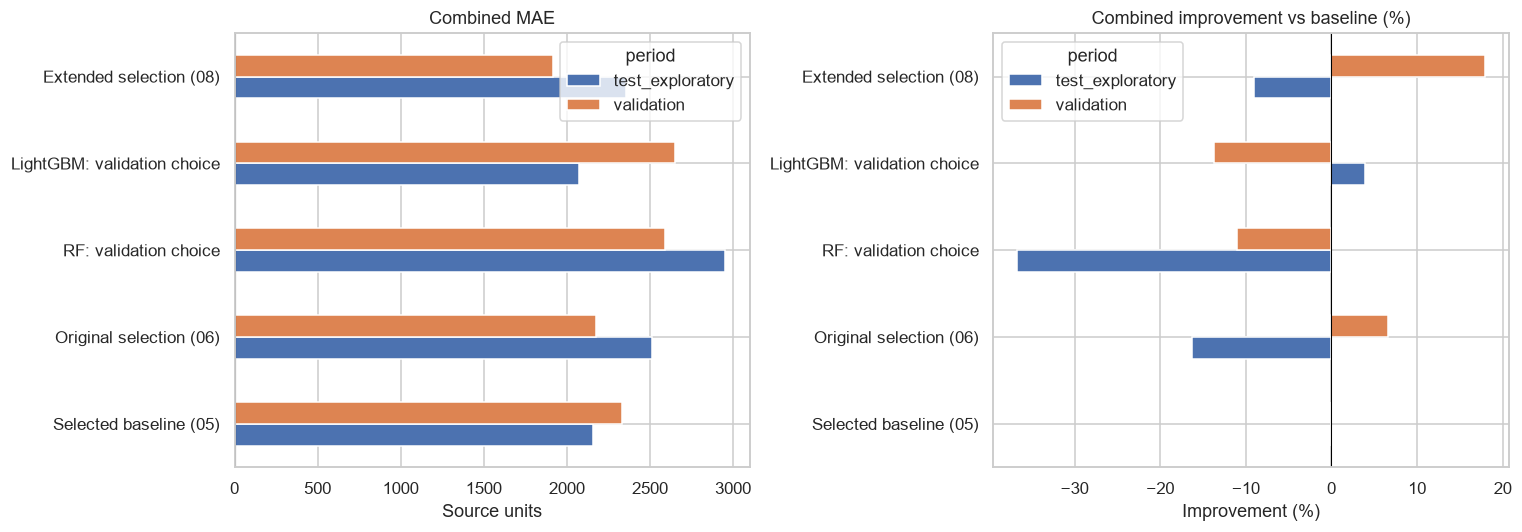

In [9]:
all_scores = pd.concat([val_scores,test_scores],ignore_index=True)
comparison = all_scores.loc[all_scores.candidate.isin(show_names)].copy()
table(comparison,'08_validation_test_comparison')
display(comparison.loc[comparison.series.eq('total')].round(3))
fig,axes = plt.subplots(1,2,figsize=(14,5))
for ax,metric,title in zip(axes,['MAE','MAE_improvement_vs_baseline_pct'],['Combined MAE','Combined improvement vs baseline (%)']):
    d = comparison.loc[comparison.series.eq('total')].pivot(index='candidate',columns='period',values=metric).reindex(show_names)
    d.index = d.index.map(labels)
    d.plot.barh(ax=ax)
    ax.set(title=title,ylabel='',xlabel='Source units' if metric=='MAE' else 'Improvement (%)')
    ax.axvline(0,color='black',linewidth=.7)
figure(fig,'04_validation_vs_test')

### Read the zone results alongside the combined score

| Series | Baseline MAE | Random Forest MAE | LightGBM MAE | Extended selection MAE |
|---|---:|---:|---:|---:|
| zone1 | 977.31 | 2,189.63 | 2,616.35 | 2,444.48 |
| zone2 | 1,132.87 | 1,059.17 | 1,982.63 | 1,059.17 |
| zone3 | 854.13 | 877.54 | 882.86 | 1,694.59 |
| total | 2,159.19 | 2,952.61 | 2,074.75 | 2,354.44 |

Combined MAE is calculated after summing forecasts, not by adding the three zone MAEs. Overprediction in one zone can offset underprediction in another. The saved score table includes signed bias to help identify this cancellation.

## 10. Forecast shapes and daily error patterns
The first seven test days are selected by a fixed chronological rule. Daily MAE averages all 144 targets, and every test day is included. These plots reveal sustained bias and isolated difficult days; they supplement the full-period scores.

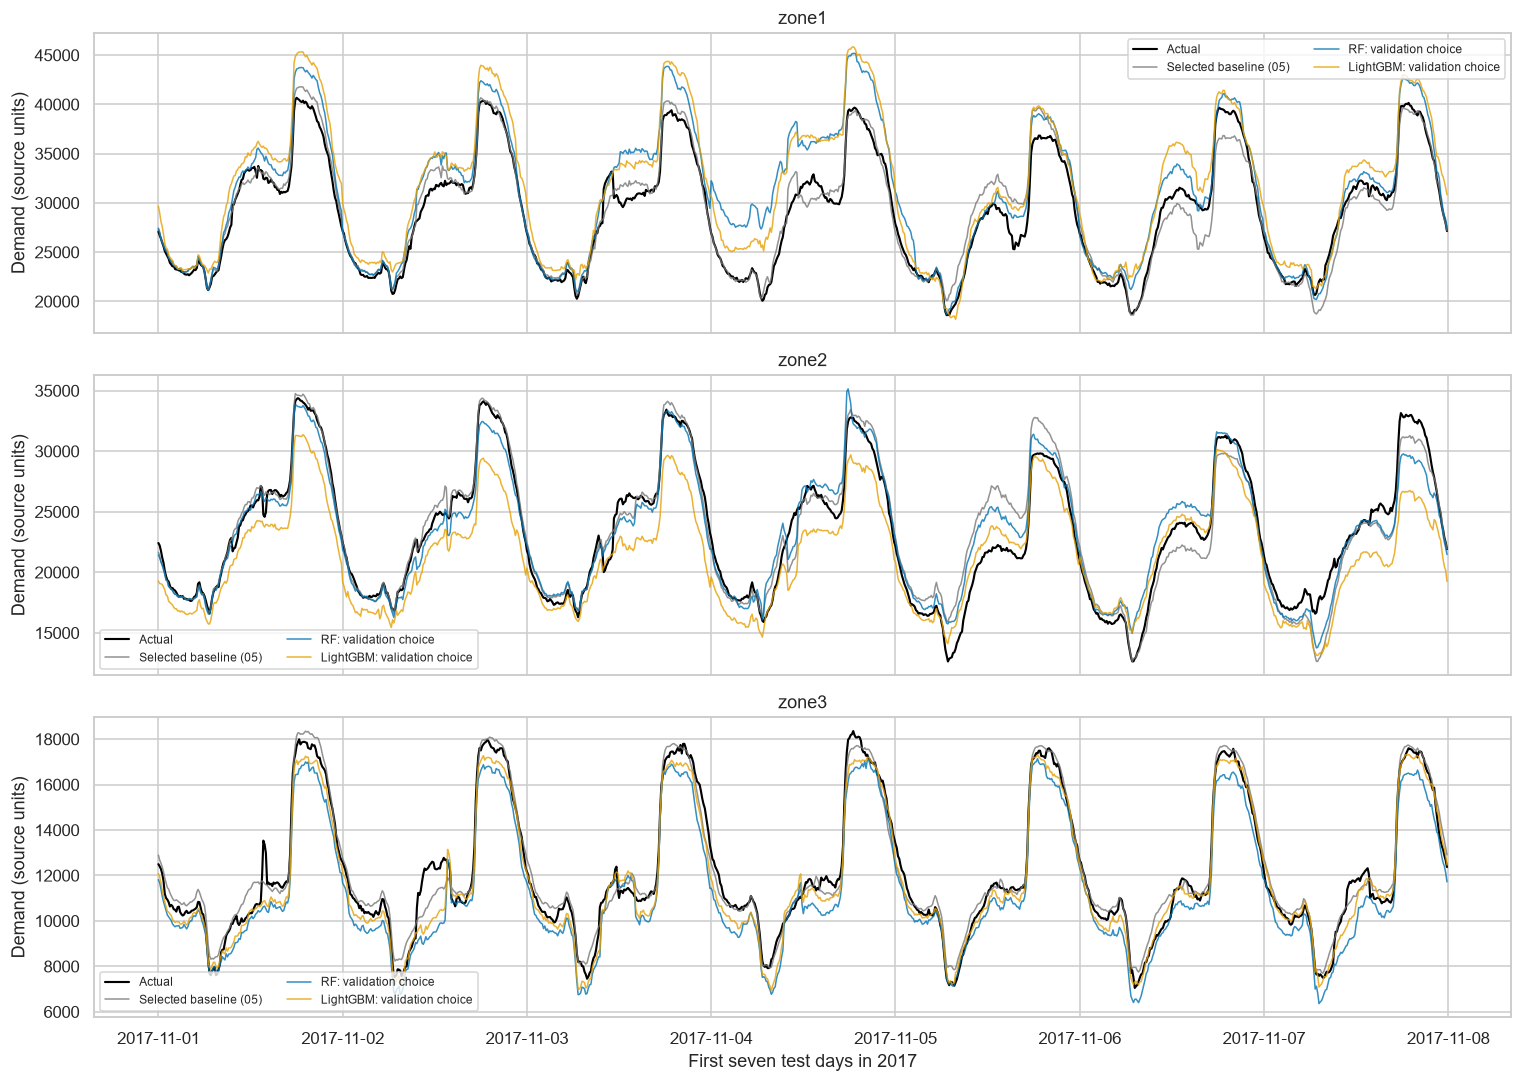

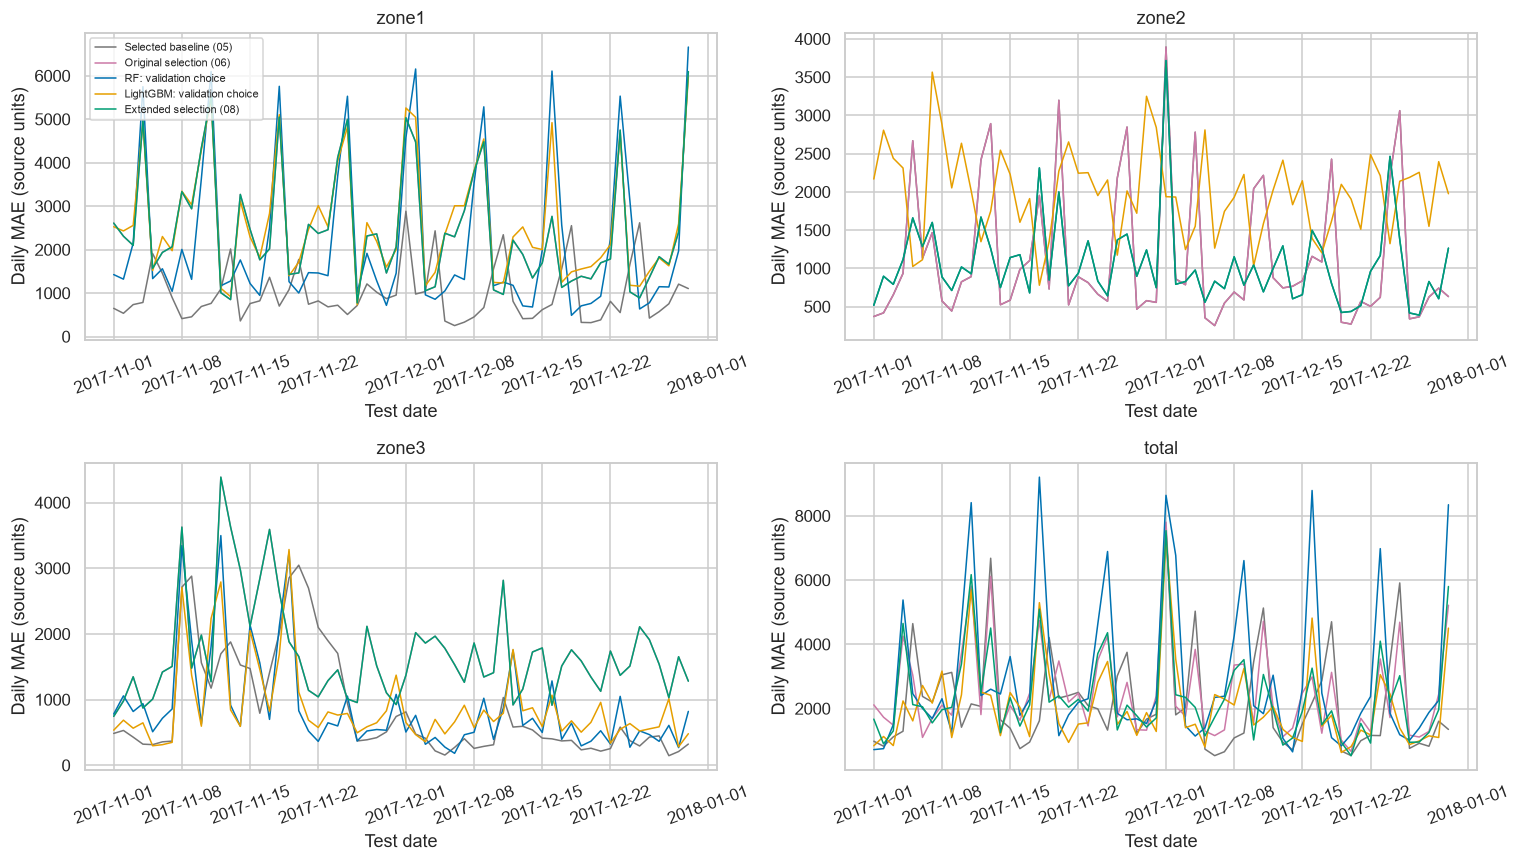

In [10]:
window = actual_test.index < actual_test.index.min()+pd.Timedelta(days=7)
fig,axes = plt.subplots(3,1,figsize=(14,10),sharex=True)
for ax,z in zip(axes,ZONES):
    ax.plot(actual_test.index[window],actual_test.loc[window,z],color='black',label='Actual',linewidth=1.4)
    for n in ['baseline','rf_selected','lgbm_selected']:
        ax.plot(actual_test.index[window],test_predictions[n].loc[window,z],label=labels[n],color=colours[n],alpha=.8,linewidth=1)
    ax.set(title=z,ylabel='Demand (source units)'); ax.legend(fontsize=8,ncol=2)
axes[-1].set_xlabel('First seven test days in 2017')
figure(fig,'05_first_test_week')
daily_frames = []
fig,axes = plt.subplots(2,2,figsize=(14,8))
for n in show_names:
    d = (test_predictions[n]-actual_test).abs().resample('D').mean()
    daily_frames.append(d.rename_axis('date').reset_index().melt(id_vars='date',var_name='series',value_name='MAE').assign(candidate=n))
    for ax,z in zip(axes.flat,SERIES):
        ax.plot(d.index,d[z],label=labels[n],color=colours[n],linewidth=1)
        ax.set(title=z,ylabel='Daily MAE (source units)',xlabel='Test date'); ax.tick_params(axis='x',rotation=20)
axes[0,0].legend(fontsize=7)
table(pd.concat(daily_frames,ignore_index=True),'09_test_daily_mae')
figure(fig,'06_daily_test_mae')

## 11. Lead slots and historical peak warnings
Lead length and target clock time move together at a fixed issue time. Each lead slot has 60 test observations, so these curves do not isolate a causal effect of forecast distance.

Retain Notebook 07's training-only 95th-percentile thresholds. Compare forecast >= threshold with actual >= threshold. These indicate historical high demand, not capacity limits. A ratio with denominator zero is undefined (NaN). Only Zone 2 has positive peaks in this test period, so the chart focuses there; the table retains all zones and false alerts. Peak scores do not change model selection or thresholds.

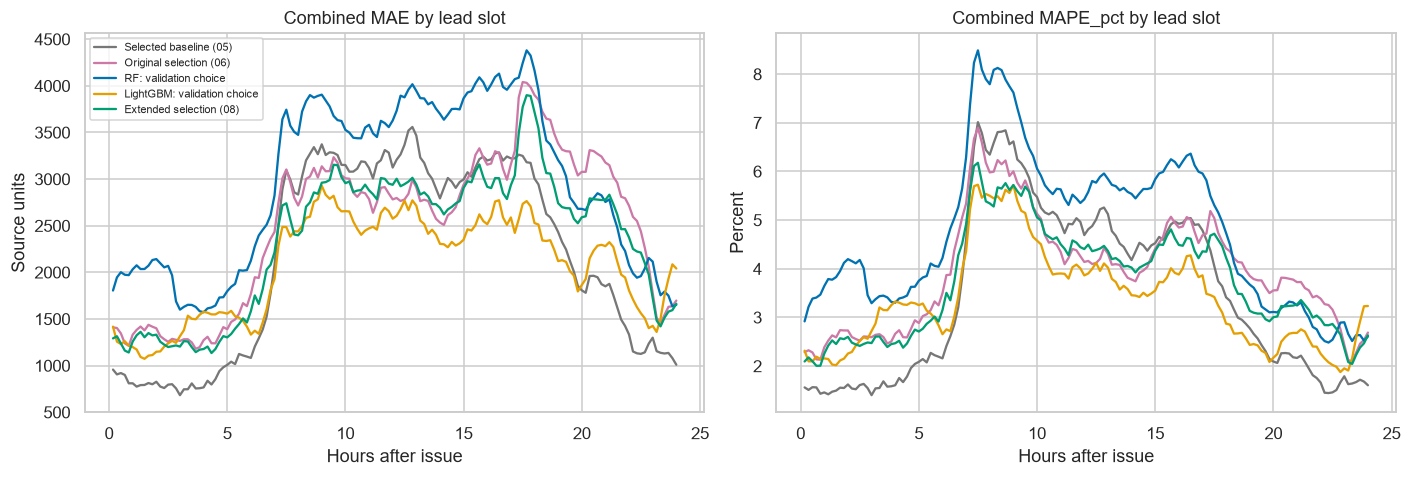

,candidate,series,threshold,actual_peaks,warnings,TP,FP,FN,TN,precision,recall,F1,false_positive_rate
0,baseline,zone1,45037.3983,0,0,0,0,0,8640,NaN,NaN,NaN,0.0000
1,baseline,zone2,29206.3291,1595,1595,1461,134,134,6911,0.9160,0.9160,0.9160,0.0190
2,baseline,zone3,32397.0273,0,0,0,0,0,8640,NaN,NaN,NaN,0.0000
3,baseline,total,103272.9341,0,0,0,0,0,8640,NaN,NaN,NaN,0.0000
4,original_selected,zone1,45037.3983,0,166,0,166,0,8474,0.0000,NaN,0.0000,0.0192
5,original_selected,zone2,29206.3291,1595,1595,1461,134,134,6911,0.9160,0.9160,0.9160,0.0190
6,original_selected,zone3,32397.0273,0,0,0,0,0,8640,NaN,NaN,NaN,0.0000
7,original_selected,total,103272.9341,0,0,0,0,0,8640,NaN,NaN,NaN,0.0000
24,rf_selected,zone1,45037.3983,0,54,0,54,0,8586,0.0000,NaN,0.0000,0.0062
25,rf_selected,zone2,29206.3291,1595,1518,1420,98,175,6947,0.9354,0.8903,0.9123,0.0139


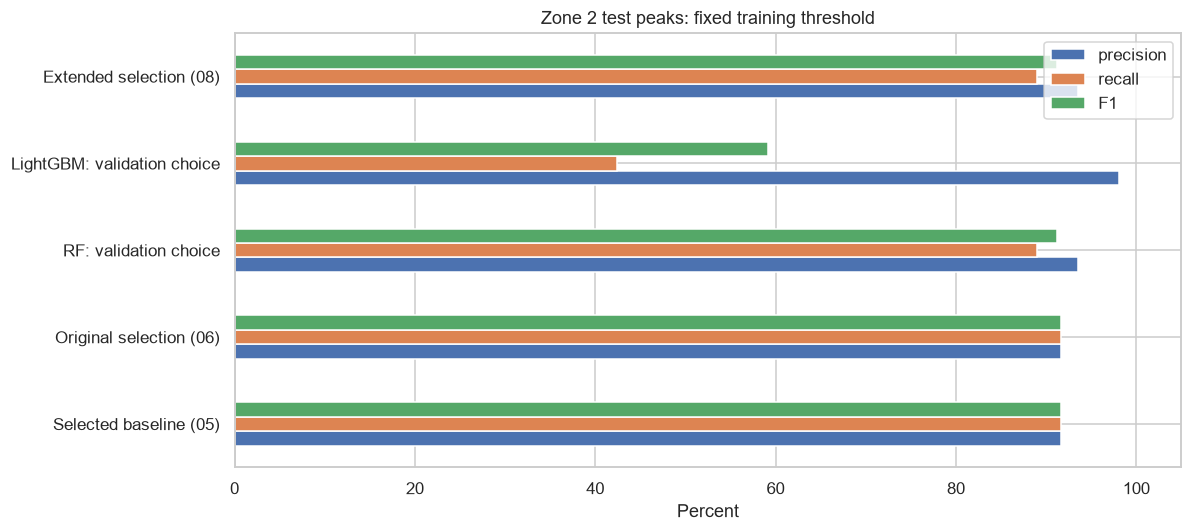

In [11]:
lead_rows = []
fig,axes = plt.subplots(1,2,figsize=(13,4.5))
for n in show_names:
    e = test_predictions[n]-actual_test
    lead = pd.DataFrame(dict(lead_steps=test.lead_steps, MAE=np.abs(e.total.to_numpy()),
                            MAPE_pct=100*np.abs(e.total.to_numpy())/actual_test.total.to_numpy())).groupby('lead_steps').mean()
    lead_rows.append(lead.reset_index().assign(candidate=n))
    for ax,metric in zip(axes,['MAE','MAPE_pct']):
        ax.plot(lead.index/6,lead[metric],color=colours[n],label=labels[n])
        ax.set(title=f'Combined {metric} by lead slot',xlabel='Hours after issue',ylabel='Source units' if metric=='MAE' else 'Percent')
axes[0].legend(fontsize=7)
table(pd.concat(lead_rows,ignore_index=True),'10_test_combined_lead_errors')
figure(fig,'07_test_lead_errors')
def ratio(a,b): return a/b if b else np.nan
peak_rows = []
for n,f in test_predictions.items():
    for z in SERIES:
        threshold = peak_plan['thresholds'][z]
        np.testing.assert_allclose(threshold,actual_frame(train)[z].quantile(.95),rtol=1e-12)
        y,p = actual_test[z].to_numpy()>=threshold, f[z].to_numpy()>=threshold
        tp,fp,fn,tn = [int(x.sum()) for x in [y&p,~y&p,y&~p,~y&~p]]
        peak_rows.append(dict(candidate=n,series=z,threshold=threshold,actual_peaks=int(y.sum()),warnings=int(p.sum()),
                              TP=tp,FP=fp,FN=fn,TN=tn,precision=ratio(tp,tp+fp),recall=ratio(tp,tp+fn),
                              F1=ratio(2*tp,2*tp+fp+fn),false_positive_rate=ratio(fp,fp+tn)))
peak_scores = pd.DataFrame(peak_rows)
table(peak_scores,'11_test_peak_warning_scores')
display(peak_scores.loc[peak_scores.candidate.isin(show_names)].round(4))
fig,ax = plt.subplots(figsize=(11,5))
d = peak_scores.loc[peak_scores.series.eq('zone2')].set_index('candidate').loc[show_names,['precision','recall','F1']]
d.index = d.index.map(labels)
(100*d).plot.barh(ax=ax)
ax.set(title='Zone 2 test peaks: fixed training threshold',xlabel='Percent',ylabel='',xlim=(0,105))
figure(fig,'08_zone2_peak_scores')

### Measured peak-warning findings

| Strategy | Zone 2 precision | Zone 2 recall | False alerts | Missed peaks |
|---|---:|---:|---:|---:|
| Selected baseline (05) | 91.60% | 91.60% | 134 | 134 |
| Original selection (06) | 91.60% | 91.60% | 134 | 134 |
| Random Forest | 93.54% | 89.03% | 98 | 175 |
| LightGBM | 98.11% | 42.38% | 13 | 919 |
| Extended selection (08) | 93.54% | 89.03% | 98 | 175 |

Zone 2 has **1,595** positive test readings. Zones 1 and 3 and combined demand have zero positive readings under the fixed thresholds, so their recall cannot be estimated. False alerts still matter and remain visible in the full table. These pointwise warning scores do not measure whole-event detection or calibrated probabilities.

## 12. Save reproducible results
The prediction export includes actual outcomes for retrospective analysis. It is not a future production forecast file. Verify source data, earlier models and earlier outputs are unchanged. Hardware and software versions can affect runtimes and small numerical details; the saved plan records the environment used here.

In [12]:
parts = []
for period,d,a,predictions in [('validation',val,actual_val,val_predictions),('test_exploratory',test,actual_test,test_predictions)]:
    for n,f in predictions.items():
        for z in SERIES:
            parts.append(pd.DataFrame(dict(period=period,candidate=n,series=z,origin_time=d.origin_time.to_numpy(),
                target_time=a.index,lead_steps=d.lead_steps.to_numpy(),actual=a[z].to_numpy(),prediction=f[z].to_numpy())))
prediction_path = PROCESSED_DIR/'extended_model_predictions_daily_batch.parquet'
pd.concat(parts,ignore_index=True).to_parquet(prediction_path,index=False)
for path,digest in protected_hashes.items(): assert sha(ROOT/path)==digest, f'Input changed: {path}'
for path,digest in new_model_hashes.items(): assert sha(ROOT/path)==digest, f'Model changed: {path}'
assert sha(plan_path)==plan_hash
combined = comparison.loc[comparison.series.eq('total')].copy()
table(combined,'12_combined_summary')
result = dict(design_id=manifest['design_id'],exploratory=True,test_previously_inspected=True,test_scored=True,
              experiment_plan_sha256=plan_hash,selection_sha256=sha(selection_path),choices=choices,
              fit_latest_label=str(train.target_time.max()),metrics=json.loads(all_scores.to_json(orient='records')),
              peak_metrics=json.loads(peak_scores.to_json(orient='records')),prediction_file=str(prediction_path.relative_to(ROOT)),
              prediction_sha256=sha(prediction_path),model_reselected_after_test=False,prior_files_unchanged=True)
(MOD/'extension_results.json').write_text(json.dumps(result,indent=2,allow_nan=False),encoding='utf-8')
print('PASS: saved models reload correctly; original input and model hashes unchanged.')
display(combined[['period','candidate','MAE','RMSE','MAPE_pct','MAE_improvement_vs_baseline_pct']].round(3))

PASS: saved models reload correctly; original input and model hashes unchanged.


,period,candidate,MAE,RMSE,MAPE_pct,MAE_improvement_vs_baseline_pct
3,validation,baseline,2333.079,3489.827,3.612,0.000
39,validation,original_selected,2177.868,2915.440,3.332,6.653
43,validation,rf_selected,2591.652,3204.146,3.967,-11.083
47,validation,lgbm_selected,2653.273,3208.429,3.985,-13.724
51,validation,extended_selected,1914.012,2594.287,2.903,17.962
55,test_exploratory,baseline,2159.186,3234.920,3.456,0.000
59,test_exploratory,original_selected,2512.191,3382.994,3.938,-16.349
79,test_exploratory,rf_selected,2952.614,4144.004,4.761,-36.747
83,test_exploratory,lgbm_selected,2074.750,2814.071,3.359,3.911
87,test_exploratory,extended_selected,2354.439,3192.949,3.715,-9.043


## Discussion for the defence
- Explain common forecast timing, available predictors and the residual target before discussing algorithm rankings.
- Use the frozen validation choices in the later-period comparison. A retrospective test leaderboard does not provide new independent selection evidence.
- A baseline can win; a new model can also improve this particular period without being universally best.
- Discuss zone-level bias and error cancellation in the combined forecast.
- Peak detection is a separate evaluation, and missing positive cases limit conclusions.
- These findings apply to the declared configurations and periods. Further tuning requires a declared validation design and new independent data for confirmation.

The measured findings above come from the executed notebook. Preserve both favourable and unfavourable comparisons in the report. The earlier Notebook 07 results remain valid for its original models; this notebook adds evidence for two further model families under the same forecast timing.